## assignment 1.

ToDo: 
- mathematically prove the boundary of sphere and torus for case a and b. use that as a bounding box. (+ error margin?)

- make a function for generating the needed data

- generate table / figure






In [ ]:
import math


def tight_bounding_box(k, R, r):
    """Smallest box [xmin, xmax, ymin, ymax, zmin, zmax] that contains the intersection of the sphere (radius k)
    and the torus (major radius R, minor radius r), both centered at the origin, assuming R >= r and k > R - r.
    With rho = sqrt(x^2 + y^2) the shapes are two discs in the (rho, z) plane: center (0, 0) with radius k,
    and center (R, 0) with radius r. The box follows from the largest rho and the largest |z| of their overlap."""
    # largest rho, reached at z = 0: the edge of the sphere (k) or the outer edge of the tube (R + r)
    rho_max = min(k, R + r)
    if R**2 + r**2 <= k**2:
        z_max = r  # the top of the tube (R, r) lies inside the sphere
    else:
        rho_cross = (k**2 + R**2 - r**2) / (2 * R)  # rho where the two circles cross
        z_max = math.sqrt(k**2 - rho_cross**2)      # the top of the overlap is that crossing point
    return [-rho_max, rho_max, -rho_max, rho_max, -z_max, z_max]


for name, (k, R, r) in {"case a": (1, 0.75, 0.4), "case b": (1, 0.5, 0.5)}.items():
    print(f"{name}: tight bounding box B* = {tight_bounding_box(k, R, r)}")

In [53]:
import math
import random as random

def sphere_eq(x, y, z, k):
    """ k is the radius of the sphere. 
    The function returns True if the point (x, y, z) is on
     the surface of the sphere with radius k centered at the 
     origin."""
    return x**2 + y**2 + z**2 <= k**2

def torus_eq(x, y, z, R, r):
    """ R is the distance from the center of the tube to the center of the torus,
    and r is the radius of the tube. 
    The function returns True if the point (x, y, z) is on
    the surface of the torus with major radius R and minor radius r centered at the 
    origin."""
    return ((x**2 + y**2)**0.5 - R)**2 + z**2 <= r**2

def intersection_eq(x, y, z, k, R, r):
    """Returns True if the point (x, y, z) is inside both the sphere with radius k
    and the torus with major radius R and minor radius r (both centered at the origin)."""
    return sphere_eq(x, y, z, k) and torus_eq(x, y, z, R, r)

def generate_points(n, bounds):
    """Generates n random points within the given bounds.
    bounds is a list of 6 values: [xmin, xmax, ymin, ymax, zmin, zmax]"""
    points = []
    for _ in range(n):
        x = random.uniform(bounds[0], bounds[1])
        y = random.uniform(bounds[2], bounds[3])
        z = random.uniform(bounds[4], bounds[5])
        points.append((x, y, z))
    return points

def count_points_in_shape(points, shape_func, *shape_params):
    """Counts how many points from the list are inside the shape defined by shape_func.
    shape_func is a function that takes x, y, z and shape parameters and returns True if the point is inside the shape."""
    count = 0
    for point in points:
        if shape_func(*point, *shape_params):
            count += 1
    return count

def box_volume(bounds):
    """Volume of the box [xmin, xmax, ymin, ymax, zmin, zmax]."""
    return (bounds[1] - bounds[0]) * (bounds[3] - bounds[2]) * (bounds[5] - bounds[4])

def estimate_volume(count, total_points, bounds):
    """Estimates the volume of a shape based on the count of points inside it, total points generated, and the bounding box."""
    return box_volume(bounds) * (count / total_points)

def standard_error(count, total_points, bounds):
    """Standard error of the volume estimate: V_box * sqrt(p * (1 - p) / n), with p the fraction of points inside."""
    p = count / total_points
    return box_volume(bounds) * math.sqrt(p * (1 - p) / total_points)


n = 100000  # Number of random points to generate

# Bounding box B: the intersection lies inside the sphere, so [-k, k]^3 (k = 1) fully contains it
bounds_B = [-1, 1, -1, 1, -0.5, 0.5]

cases = {"a": (1, 0.75, 0.4), "b": (1, 0.5, 0.5)}  # case: (k, R, r)

results_uniform = {}
for case, (k, R, r) in cases.items():
    points = generate_points(n, bounds_B)
    count = count_points_in_shape(points, intersection_eq, k, R, r)
    volume = estimate_volume(count, n, bounds_B)
    error = standard_error(count, n, bounds_B)
    results_uniform[case] = (volume, error)
    print(f"case {case}: count = {count} of {n} points are in the intersection")
    print(f"case {case}: estimated volume of the intersection: {volume:.4f} ± {1.96 * error:.4f} (95% confidence interval)")


case a: count = 46445 of 100000 points are in the intersection
case a: estimated volume of the intersection: 1.8578 ± 0.0124 (95% confidence interval)
case b: count = 61719 of 100000 points are in the intersection
case b: estimated volume of the intersection: 2.4688 ± 0.0121 (95% confidence interval)


In [54]:
import numpy as np
import plotly.graph_objects as go
from itertools import combinations, product


def implicit_surface(inside, bounds, h, name, color, opacity, visible=True):
    """Draws the boundary of the region where inside(X, Y, Z) is True.
    bounds = ((xmin, xmax), (ymin, ymax), (zmin, zmax)) is the region to evaluate on,
    h is the grid spacing (smaller = smoother surface but larger output).
    Each grid cell is evaluated at 2x2x2 sub-points and the inside-count is contoured,
    which gives a much smoother surface than contouring a plain True/False grid."""
    axes = [np.arange(lo - 2*h, hi + 2.5*h, h, dtype=np.float32) for lo, hi in bounds]
    X, Y, Z = np.meshgrid(*axes, indexing="ij")
    offsets = (-h/4, h/4)
    counts = sum(inside(X + dx, Y + dy, Z + dz).astype(np.uint8)
                 for dx, dy, dz in product(offsets, repeat=3))  # 0 (outside) .. 8 (inside)
    return go.Isosurface(
        x=X.ravel(), y=Y.ravel(), z=Z.ravel(), value=counts.ravel(),
        isomin=4, isomax=4, surface_count=1,
        caps=dict(x_show=False, y_show=False, z_show=False),
        colorscale=[[0, color], [1, color]], showscale=False, flatshading=False,
        opacity=opacity, name=name, showlegend=True, visible=visible,
        hovertemplate=name + "<br>x=%{x:.2f}, y=%{y:.2f}, z=%{z:.2f}<extra></extra>",
    )


def box_wireframe(bounds, name, color):
    """Draws the 12 edges of the box ((xmin, xmax), (ymin, ymax), (zmin, zmax))."""
    corners = list(product(*bounds))
    xs, ys, zs = [], [], []
    for a, b in combinations(corners, 2):
        if sum(ai != bi for ai, bi in zip(a, b)) == 1:  # corners differ in one coordinate -> edge
            xs += [a[0], b[0], None]
            ys += [a[1], b[1], None]
            zs += [a[2], b[2], None]
    return go.Scatter3d(x=xs, y=ys, z=zs, mode="lines", line=dict(color=color, width=5),
                        name=name, hoverinfo="name")


def plot_sphere_torus(k, R, r, torus_center=(0, 0, 0), boxes=None, h=0.06, title=None):
    """Interactive plot of the sphere (sphere_eq) and torus (torus_eq) from the cell above.
    torus_center shifts the torus for the off-center case.
    boxes is a dict {name: ((xmin, xmax), (ymin, ymax), (zmin, zmax))} of bounding boxes to overlay.
    Click legend entries to show/hide shapes; the intersection starts hidden."""
    xc, yc, zc = torus_center

    def sphere(X, Y, Z):
        return sphere_eq(X, Y, Z, k)

    def torus(X, Y, Z):
        return torus_eq(X - xc, Y - yc, Z - zc, R, r)

    sphere_bounds = ((-k, k), (-k, k), (-k, k))
    torus_bounds = ((xc - R - r, xc + R + r), (yc - R - r, yc + R + r), (zc - r, zc + r))
    overlap_bounds = tuple((max(s0, t0), min(s1, t1))
                           for (s0, s1), (t0, t1) in zip(sphere_bounds, torus_bounds))

    traces = [
        implicit_surface(sphere, sphere_bounds, h, f"Sphere (k={k})", "#2a78d6", 0.2),
        implicit_surface(torus, torus_bounds, h, f"Torus (R={R}, r={r})", "#eb6834", 0.85),
        implicit_surface(lambda X, Y, Z: sphere(X, Y, Z) & torus(X, Y, Z), overlap_bounds, h,
                         "Intersection", "#1baf7a", 1.0, visible="legendonly"),
    ]
    box_colors = ["#52514e", "#6250d6", "#e87ba4"]
    for (name, bounds), color in zip((boxes or {}).items(), box_colors):
        traces.append(box_wireframe(bounds, name, color))

    fig = go.Figure(traces)
    fig.update_layout(
        title=title, height=650, margin=dict(l=0, r=0, t=40, b=0),
        legend=dict(x=0.01, y=0.98),
        scene=dict(aspectmode="data", xaxis_title="x", yaxis_title="y", zaxis_title="z"),
    )
    return fig


# Case a, with the box B = [-1, 1]^3
fig = plot_sphere_torus(k=1, R=0.75, r=0.4,
                        boxes={"B = [-1, 1]^3": ((-1, 1), (-1, 1), (-1, 1))},
                        title="Case a: k=1, R=0.75, r=0.4")
fig.show()

# Other cases, e.g.:
# plot_sphere_torus(k=1, R=0.5, r=0.5, boxes={"B": ((-1, 1), (-1, 1), (-1, 1))}, title="Case b").show()
# plot_sphere_torus(k=1, R=0.75, r=0.4, torus_center=(0, 0, 0.1),
#                   boxes={"B": ((-1, 1), (-1, 1), (-1, 1)), "S": ((-1, 1), (-1, 1), (-0.3, 0.5))},
#                   title="Part 3: off-center torus").show()

In [55]:
# 2. generate detereministic points in the bounding box
#  and check if they are in the intersection of the sphere and torus

def logistic_sequence(x0, n, m=3.8, burn_in=1000):
    """Returns n values of X_{n+1} = m * X_n * (1 - X_n), starting from x0.
    The first burn_in values are thrown away so the starting value has less influence."""
    x = x0
    for _ in range(burn_in):
        x = m * x * (1 - x)
    seq = []
    for _ in range(n):
        x = m * x * (1 - x)
        seq.append(x)
    return seq


n = 100000
x0 = 0.5
y0 = 0.1
z0 = 0.2

xs = logistic_sequence(x0, n)
ys = logistic_sequence(y0, n)
zs = logistic_sequence(z0, n)

# rescale from (0, 1) to the box B
xmin, xmax, ymin, ymax, zmin, zmax = bounds_B
logistic_points = [(xmin + (xmax - xmin) * u, ymin + (ymax - ymin) * v, zmin + (zmax - zmin) * w)
                   for u, v, w in zip(xs, ys, zs)]

results_logistic = {}
for case, (k, R, r) in cases.items():
    count = count_points_in_shape(logistic_points, intersection_eq, k, R, r)
    volume = estimate_volume(count, n, bounds_B)
    error = standard_error(count, n, bounds_B)
    results_logistic[case] = (volume, error)
    print(f"case {case} deterministic: count = {count} of {n} points are in the intersection")
    print(f"case {case} deterministic: estimated volume of the intersection: {volume:.4f} ± {1.96 * error:.4f} (95% confidence interval)")


case a deterministic: count = 53160 of 100000 points are in the intersection
case a deterministic: estimated volume of the intersection: 2.1264 ± 0.0124 (95% confidence interval)
case b deterministic: count = 66784 of 100000 points are in the intersection
case b deterministic: estimated volume of the intersection: 2.6714 ± 0.0117 (95% confidence interval)


In [56]:
# 3

def off_center_torus(X, Y, Z, R, r, center):
    """R is the distance from the center of the tube to the center of the torus,
    and r is the radius of the tube. 
    The function returns True if the point (X, Y, Z) is on
    the surface of the torus with major radius R and minor radius r centered at the 
    specified center."""
    xc, yc, zc = center
    return (((X - xc)**2 + (Y - yc)**2)**0.5 - R)**2 + (Z - zc)**2 <= r**2


Case a: k=1, R=0.75, r=0.4: reference V = 1.8561 | B*: 1.8551 ± 0.0098 | [-1, 1]^3: 1.8426 ± 0.0209 (95% CI)
Case b: k=1, R=0.5, r=0.5: reference V = 2.4674 | B*: 2.4714 ± 0.0120 | [-1, 1]^3: 2.4737 ± 0.0229 (95% CI)


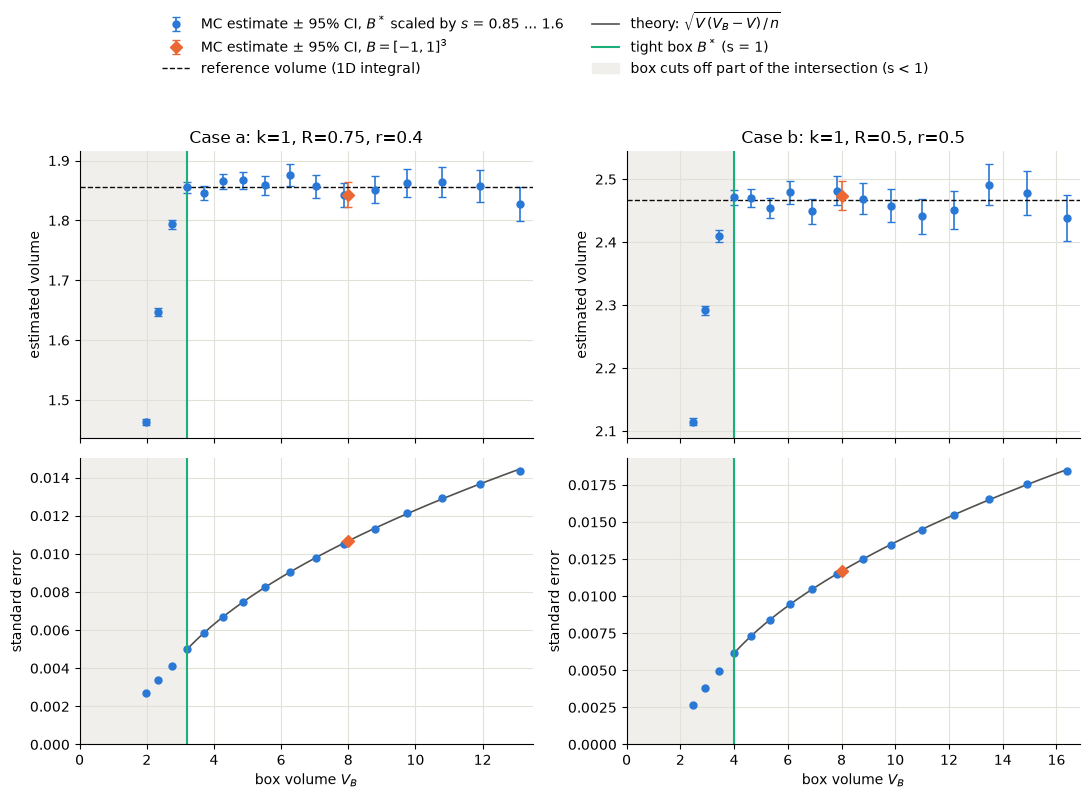

In [58]:
# Estimated volume for different bounding boxes.
# Every box is the tight box B* scaled about its center by a factor s (all side lengths times s):
# s < 1 cuts off part of the intersection, s > 1 only adds empty space.
# The sphere's box [-1, 1]^3 is added for comparison.
import numpy as np
import matplotlib.pyplot as plt


def reference_volume(k, R, r, m=200001):
    """Volume of the intersection from a fine 1D integral over z, used as a reference line.
    At height z the intersection is a ring rho_in <= rho <= rho_out with area pi * (rho_out^2 - rho_in^2)."""
    z = np.linspace(-r, r, m)
    half_width = np.sqrt(np.clip(r**2 - z**2, 0, None))  # half the width of the tube at height z
    rho_out = np.minimum(np.sqrt(np.clip(k**2 - z**2, 0, None)), R + half_width)
    rho_in = R - half_width
    return np.trapezoid(np.pi * np.clip(rho_out**2 - rho_in**2, 0, None), z)


def scaled_box(bounds, s):
    """Box with the same center as bounds and all side lengths multiplied by s."""
    new_bounds = []
    for lo, hi in zip(bounds[::2], bounds[1::2]):
        mid, half = (lo + hi) / 2, s * (hi - lo) / 2
        new_bounds += [mid - half, mid + half]
    return new_bounds


def mc_volume(k, R, r, bounds, n, rng):
    """Uniform Monte Carlo estimate of the intersection volume using the box bounds: (volume, standard error)."""
    x, y, z = rng.uniform(bounds[::2], bounds[1::2], size=(n, 3)).T
    count = int(np.sum(sphere_eq(x, y, z, k) & torus_eq(x, y, z, R, r)))
    return estimate_volume(count, n, bounds), standard_error(count, n, bounds)


n = 100000
rng = np.random.default_rng(1)
scales = np.round(np.linspace(0.85, 1.6, 16), 2)
configs = {"Case a: k=1, R=0.75, r=0.4": (1, 0.75, 0.4),
           "Case b: k=1, R=0.5, r=0.5": (1, 0.5, 0.5)}

BLUE, ORANGE, AQUA, INK, MUTED, GRID, SHADE = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e1e0d9", "#f0efec"
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex="col")

for col, (title, (k, R, r)) in enumerate(configs.items()):
    B_tight = tight_bounding_box(k, R, r)
    B_cube = [-k, k, -k, k, -k, k]
    V_tight, V_cube = box_volume(B_tight), box_volume(B_cube)
    V_boxes = V_tight * scales**3
    est, err = np.array([mc_volume(k, R, r, scaled_box(B_tight, s), n, rng) for s in scales]).T
    est_cube, err_cube = mc_volume(k, R, r, B_cube, n, rng)
    V_ref = reference_volume(k, R, r)

    i = np.argmin(np.abs(scales - 1))  # s = 1 is the tight box itself
    print(f"{title}: reference V = {V_ref:.4f} | B*: {est[i]:.4f} ± {1.96 * err[i]:.4f} | "
          f"[-1, 1]^3: {est_cube:.4f} ± {1.96 * err_cube:.4f} (95% CI)")

    top, bottom = axes[0, col], axes[1, col]
    mc_points = top.errorbar(V_boxes, est, yerr=1.96 * err, fmt="o", color=BLUE, ms=5, elinewidth=1.2, capsize=3,
                             label=r"MC estimate ± 95% CI, $B^*$ scaled by $s$ = 0.85 ... 1.6")
    cube_point = top.errorbar(V_cube, est_cube, yerr=1.96 * err_cube, fmt="D", color=ORANGE, ms=6, elinewidth=1.2,
                              capsize=3, label=r"MC estimate ± 95% CI, $B = [-1, 1]^3$")
    ref_line = top.axhline(V_ref, color=INK, ls="--", lw=1, label="reference volume (1D integral)")
    top.set(title=title, ylabel="estimated volume")

    V_grid = np.linspace(V_tight, V_boxes.max(), 200)
    theory_line, = bottom.plot(V_grid, np.sqrt(V_ref * (V_grid - V_ref) / n), color=MUTED, lw=1.2,
                               label=r"theory: $\sqrt{V\,(V_B - V)\,/\,n}$")
    bottom.plot(V_boxes, err, "o", color=BLUE, ms=5)
    bottom.plot(V_cube, err_cube, "D", color=ORANGE, ms=6)
    bottom.set(xlabel=r"box volume $V_B$", ylabel="standard error")
    bottom.set_ylim(bottom=0)

    for ax in (top, bottom):
        cut_span = ax.axvspan(0, V_tight, color=SHADE, label="box cuts off part of the intersection (s < 1)")
        tight_line = ax.axvline(V_tight, color=AQUA, lw=1.5, label=r"tight box $B^*$ (s = 1)")
        ax.set_xlim(0, V_boxes.max() * 1.03)
        ax.grid(color=GRID, lw=0.8)
        ax.spines[["top", "right"]].set_visible(False)

fig.legend(handles=[mc_points, cube_point, ref_line, theory_line, tight_line, cut_span],
           loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.86))
plt.show()